# ✈️ Airline Passenger Satisfaction — Exploratory Data Analysis & Feature Engineering
> **Goal:** Comprehensive, simple, and clean analysis of passenger satisfaction, identifying key pain points, answering core analytical questions, and engineering high-impact predictive features.

---
### Table of Contents:
1. **Load and Understand the Dataset**
2. **Data Cleaning & Sanity Checks** (Types, Missing Values, Duplicates, Outliers)
3. **Use-Case-Specific Analytical Questions**:
   - *Q1: Which service areas receive lower ratings?*
   - *Q2: How do delays affect satisfaction?*
   - *Q3: Does class influence ratings?*
   - *Q4: How do loyal and new passengers differ?*
   - *Q5: Which routes / distance tiers have recurring issues?*
   - *Q6: Which service factor varies most?*
4. **Feature Engineering** (Creating meaningful composite & operational features)
5. **Categorical Encoding** (Binary & Ordinal transformations)
6. **Feature Selection & Dimensionality Reduction** (Random Forest Importance & PCA)
7. **Summary & Strategic Business Recommendations**


## 1. Environment Setup & Data Ingestion


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Visual styling
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
from google.colab import files
uploaded = files.upload()
# Load dataset
df = pd.read_csv('train.csv')
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


Saving train.csv to train.csv
Dataset shape: 103,904 rows x 25 columns


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied


## 2. Data Quality & Cleaning
We inspect data types, missing values, duplicate entries, and unusual ranges.


In [4]:
# Check info and missing values
print("--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicates
duplicates = df.duplicated(subset=[c for c in df.columns if c not in ['Unnamed: 0', 'id']]).sum()
print(f"\nDuplicate records: {duplicates}")

# Drop unneeded index column if present
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

# Impute missing Arrival Delay with Departure Delay
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Departure Delay in Minutes']).fillna(0.0)

print(f"Total missing values after cleaning: {df.isnull().sum().sum()}")
df.to_csv('cleaned_dataset.csv', index=False)
print("Saved: cleaned_dataset.csv")


--- Missing Values ---
Arrival Delay in Minutes    310
dtype: int64

Duplicate records: 0
Total missing values after cleaning: 0
Saved: cleaned_dataset.csv


## 3. Analytical Questions
### Q1: Which service areas receive lower ratings?


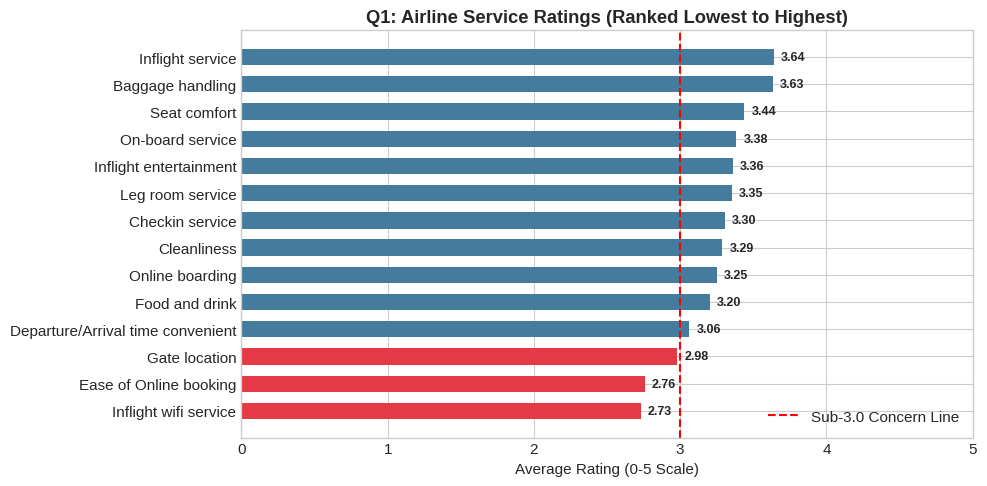

Lowest Rated Service: Inflight wifi service (2.73 / 5.0)


In [5]:
service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness'
]

# Calculate and rank average ratings
service_means = df[service_cols].mean().sort_values()

plt.figure(figsize=(10, 5))
colors = ['#e63946' if val < 3.0 else '#457b9d' for val in service_means.values]
bars = plt.barh(service_means.index, service_means.values, color=colors, height=0.6)
plt.axvline(3.0, color='red', linestyle='--', label='Sub-3.0 Concern Line')
plt.title("Q1: Airline Service Ratings (Ranked Lowest to Highest)", fontweight='bold')
plt.xlabel("Average Rating (0-5 Scale)")
plt.xlim(0, 5)
plt.legend()
for b in bars:
    plt.text(b.get_width() + 0.05, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

print(f"Lowest Rated Service: {service_means.idxmin()} ({service_means.min():.2f} / 5.0)")


### Q2: How do delays affect satisfaction?


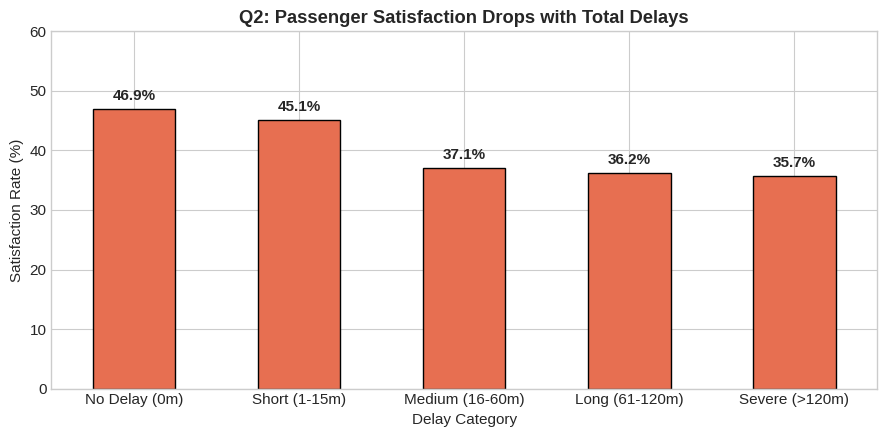

In [6]:
# Total delay calculation
df['Total Delay'] = df['Departure Delay in Minutes'] + df['Arrival Delay in Minutes']

# Delay brackets
bins = [-1, 0, 15, 60, 120, float('inf')]
labels = ['No Delay (0m)', 'Short (1-15m)', 'Medium (16-60m)', 'Long (61-120m)', 'Severe (>120m)']
df['Delay Category'] = pd.cut(df['Total Delay'], bins=bins, labels=labels)

delay_sat = df.groupby('Delay Category', observed=False)['satisfaction'].value_counts(normalize=True).unstack() * 100

plt.figure(figsize=(9, 4.5))
delay_sat['satisfied'].plot(kind='bar', color='#e76f51', edgecolor='black', width=0.5)
plt.title("Q2: Passenger Satisfaction Drops with Total Delays", fontweight='bold')
plt.ylabel("Satisfaction Rate (%)")
plt.xlabel("Delay Category")
plt.xticks(rotation=0)
for i, v in enumerate(delay_sat['satisfied']):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold')
plt.ylim(0, 60)
plt.tight_layout()
plt.show()


### Q3: Does class influence ratings?


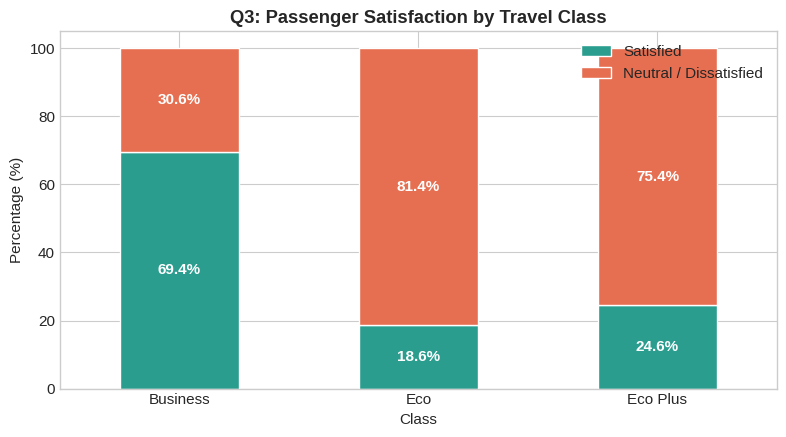

In [7]:
class_sat = df.groupby('Class')['satisfaction'].value_counts(normalize=True).unstack() * 100

ax = class_sat[['satisfied', 'neutral or dissatisfied']].plot(
    kind='bar', stacked=True, color=['#2a9d8f', '#e76f51'], figsize=(8, 4.5), edgecolor='white'
)
plt.title("Q3: Passenger Satisfaction by Travel Class", fontweight='bold')
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Satisfied", "Neutral / Dissatisfied"])
for p in ax.patches:
    height = p.get_height()
    if height > 5:
        ax.annotate(f"{height:.1f}%", (p.get_x() + p.get_width() / 2., p.get_y() + height / 2.),
                    ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()


### Q4: How do loyal and new passengers differ?


--- Loyal vs Disloyal Comparison ---
                     Age  Flight Distance  Total Delay  Satisfaction Rate (%)
Customer Type                                                                
Loyal Customer     41.39          1295.61        29.91                  47.73
disloyal Customer  30.37           714.46        30.75                  23.67


/tmp/ipykernel_2822/4277173538.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Customer Type', y=(df['satisfaction'] == 'satisfied')*100, palette=['#264653', '#2a9d8f'], ax=axes[0])


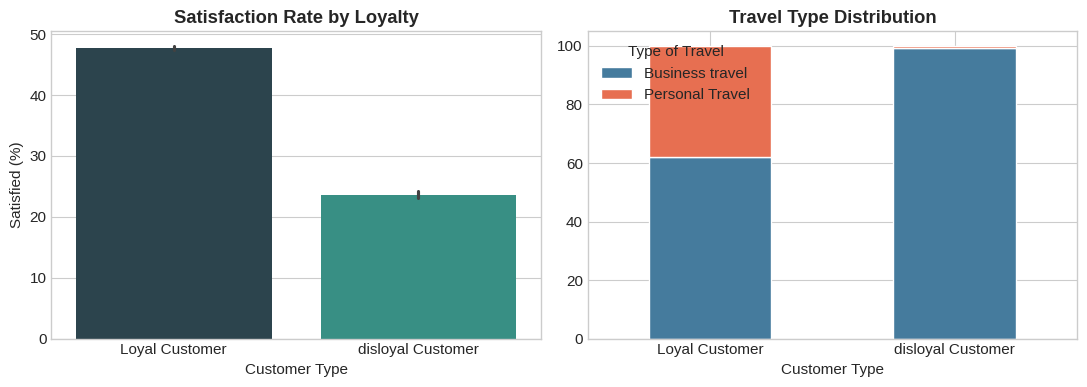

In [8]:
loyal_summary = df.groupby('Customer Type').agg({
    'Age': 'mean',
    'Flight Distance': 'mean',
    'Total Delay': 'mean',
    'satisfaction': lambda x: (x == 'satisfied').mean() * 100
}).rename(columns={'satisfaction': 'Satisfaction Rate (%)'})

print("--- Loyal vs Disloyal Comparison ---")
print(loyal_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x='Customer Type', y=(df['satisfaction'] == 'satisfied')*100, palette=['#264653', '#2a9d8f'], ax=axes[0])
axes[0].set_title("Satisfaction Rate by Loyalty", fontweight='bold')
axes[0].set_ylabel("Satisfied (%)")

pd.crosstab(df['Customer Type'], df['Type of Travel'], normalize='index').mul(100).plot(
    kind='bar', stacked=True, ax=axes[1], color=['#457b9d', '#e76f51'], edgecolor='white'
)
axes[1].set_title("Travel Type Distribution", fontweight='bold')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


### Q5: Which routes / distance tiers have recurring issues?


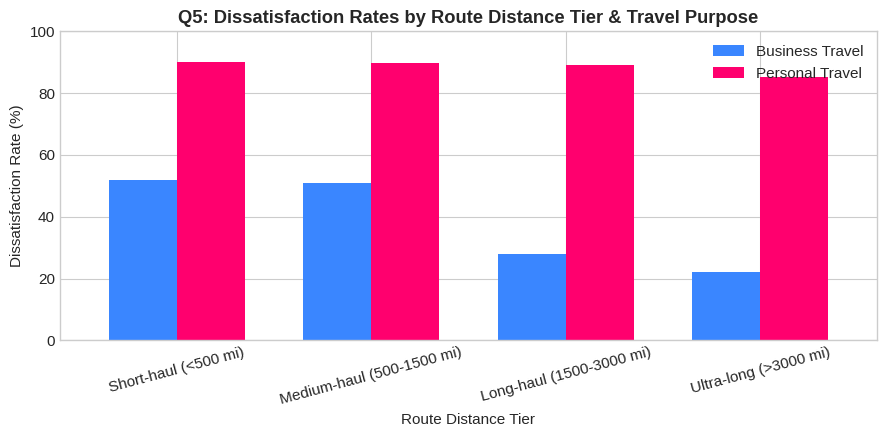

In [9]:
dist_bins = [0, 500, 1500, 3000, 10000]
dist_labels = ['Short-haul (<500 mi)', 'Medium-haul (500-1500 mi)', 'Long-haul (1500-3000 mi)', 'Ultra-long (>3000 mi)']
df['Route Distance Tier'] = pd.cut(df['Flight Distance'], bins=dist_bins, labels=dist_labels)

pivot_dissat = df.groupby(['Route Distance Tier', 'Type of Travel'], observed=False)['satisfaction']\
    .apply(lambda x: (x == 'neutral or dissatisfied').mean() * 100).unstack()

pivot_dissat.plot(kind='bar', color=['#3a86ff', '#ff006e'], figsize=(9, 4.5), width=0.7)
plt.title("Q5: Dissatisfaction Rates by Route Distance Tier & Travel Purpose", fontweight='bold')
plt.ylabel("Dissatisfaction Rate (%)")
plt.xlabel("Route Distance Tier")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.legend(["Business Travel", "Personal Travel"])
plt.tight_layout()
plt.show()


### Q6: Which service factor varies most?


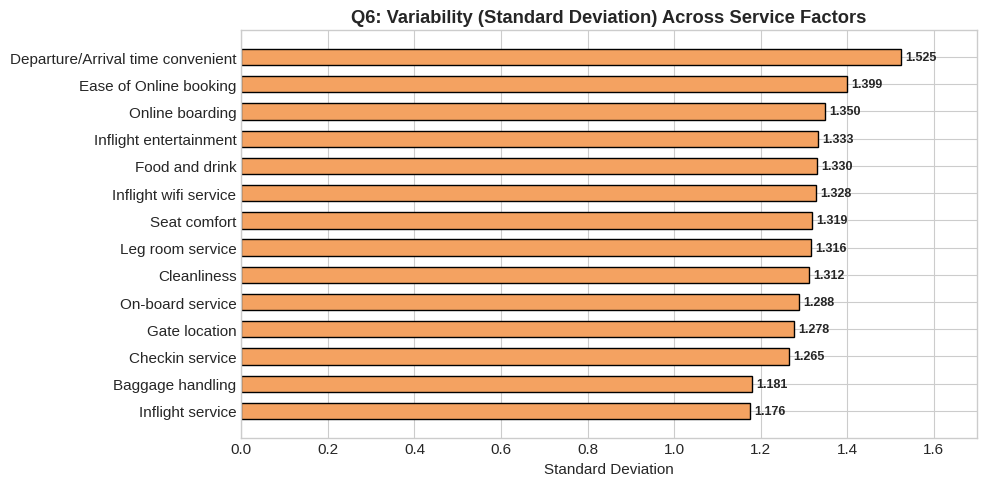

Most Variable Factor: Departure/Arrival time convenient (Std: 1.525)


In [10]:
service_std = df[service_cols].std().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.barh(service_std.index[::-1], service_std.values[::-1], color='#f4a261', edgecolor='black', height=0.6)
plt.title("Q6: Variability (Standard Deviation) Across Service Factors", fontweight='bold')
plt.xlabel("Standard Deviation")
for b in bars:
    plt.text(b.get_width() + 0.01, b.get_y() + b.get_height()/2, f"{b.get_width():.3f}", va='center', fontweight='bold', fontsize=9)
plt.xlim(0, 1.7)
plt.tight_layout()
plt.show()

print(f"Most Variable Factor: {service_std.index[0]} (Std: {service_std.iloc[0]:.3f})")


## 4. Feature Engineering
We construct domain-specific composite features that capture broader customer experiences.


In [11]:
df_feat = df.copy()

# Feature 1: Total Delay & Delay Flag
df_feat['Total_Delay'] = df_feat['Departure Delay in Minutes'] + df_feat['Arrival Delay in Minutes']
df_feat['Is_Delayed'] = (df_feat['Total_Delay'] > 5).astype(int)

# Feature 2: Overall Service Score (Average of all 14 ratings)
df_feat['Overall_Service_Rating'] = df_feat[service_cols].mean(axis=1)

# Feature 3: Inflight Experience Score
inflight_cols = ['Seat comfort', 'Food and drink', 'Inflight entertainment', 'Leg room service', 'Cleanliness']
df_feat['Inflight_Experience_Score'] = df_feat[inflight_cols].mean(axis=1)

# Feature 4: Pre-flight & Airport Score
preflight_cols = ['Gate location', 'Departure/Arrival time convenient', 'Baggage handling', 'Checkin service']
df_feat['Preflight_Airport_Score'] = df_feat[preflight_cols].mean(axis=1)

# Feature 5: Digital Experience Score
digital_cols = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
df_feat['Digital_Experience_Score'] = df_feat[digital_cols].mean(axis=1)

# Feature 6: Delay Recovery Ratio
df_feat['Delay_Recovery_Ratio'] = (df_feat['Arrival Delay in Minutes'] + 1) / (df_feat['Departure Delay in Minutes'] + 1)

df_feat.to_csv('engineered_features.csv', index=False)
print("Saved: engineered_features.csv with 7 newly engineered features!")
df_feat[['Total_Delay', 'Is_Delayed', 'Overall_Service_Rating', 'Inflight_Experience_Score', 'Digital_Experience_Score']].head()


Saved: engineered_features.csv with 7 newly engineered features!


,Total_Delay,Is_Delayed,Overall_Service_Rating,Inflight_Experience_Score,Digital_Experience_Score
0,43.0,1,3.857143,4.6,3.000000
1,7.0,1,2.285714,1.8,3.000000
2,0.0,0,3.714286,4.6,3.000000
3,20.0,1,3.000000,2.6,3.000000
4,0.0,0,3.500000,3.8,3.666667


## 5. Categorical Encoding
Transforming binary and ordinal features into numerical format for ML modeling.


In [12]:
df_encoded = df_feat.copy()

# Binary Mappings
df_encoded['Gender'] = df_encoded['Gender'].map({'Female': 0, 'Male': 1})
df_encoded['Customer Type'] = df_encoded['Customer Type'].map({'disloyal Customer': 0, 'Loyal Customer': 1})
df_encoded['Type of Travel'] = df_encoded['Type of Travel'].map({'Personal Travel': 0, 'Business travel': 1})
df_encoded['satisfaction'] = df_encoded['satisfaction'].map({'neutral or dissatisfied': 0, 'satisfied': 1})

# Ordinal Class Mapping
df_encoded['Class'] = df_encoded['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})

# Drop non-predictive columns
drop_cols = ['id', 'Delay Category', 'Route Distance Tier']
df_encoded.drop(columns=[c for c in drop_cols if c in df_encoded.columns], inplace=True)

df_encoded.head(3)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Arrival Delay in Minutes,satisfaction,Total Delay,Total_Delay,Is_Delayed,Overall_Service_Rating,Inflight_Experience_Score,Preflight_Airport_Score,Digital_Experience_Score,Delay_Recovery_Ratio
0,1,1,13,0,1,460,3,4,3,1,...,18.0,0,43.0,43.0,1,3.857143,4.6,3.25,3.0,0.730769
1,1,0,25,1,2,235,3,2,3,3,...,6.0,0,7.0,7.0,1,2.285714,1.8,2.25,3.0,3.500000
2,0,1,26,1,2,1142,2,2,2,2,...,0.0,1,0.0,0.0,0,3.714286,4.6,3.00,3.0,1.000000


## 6. Feature Selection & Dimensionality Reduction
We apply **Random Forest Feature Importance** and **Principal Component Analysis (PCA)** to find key drivers.


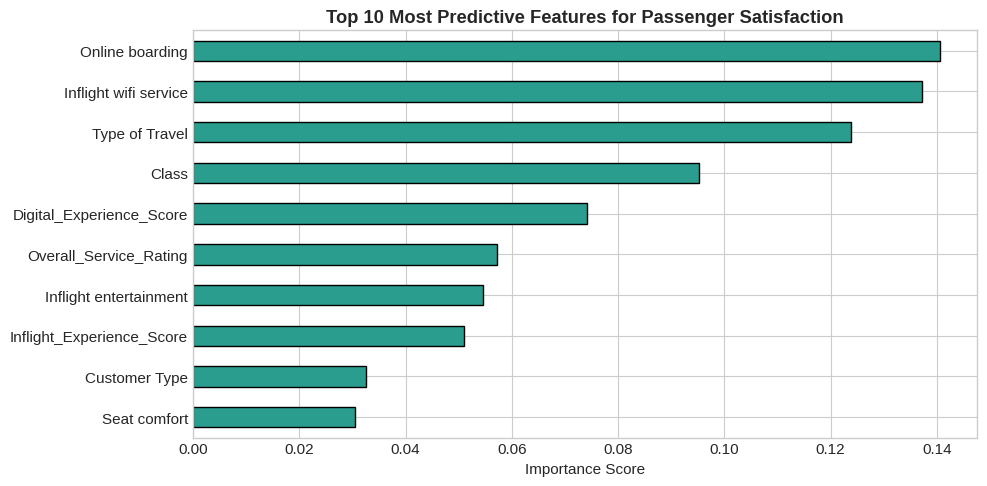

Saved: selected_features.csv

PCA Variance Explained by 3 Components: 59.49%
  • PC1: 27.14%
  • PC2: 16.87%
  • PC3: 15.47%


In [13]:
X = df_encoded.drop(columns=['satisfaction'])
y = df_encoded['satisfaction']

# Train Random Forest on representative sample for feature importance
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X.sample(n=20000, random_state=42), y.sample(n=20000, random_state=42))

feat_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.head(10).plot(kind='barh', color='#2a9d8f', edgecolor='black')
plt.gca().invert_yaxis()
plt.title("Top 10 Most Predictive Features for Passenger Satisfaction", fontweight='bold')
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# Save selected features
selected_df = pd.DataFrame({'Feature': feat_imp.index, 'Importance': feat_imp.values})
selected_df.to_csv('selected_features.csv', index=False)
print("Saved: selected_features.csv")

# PCA on 14 Service Features
scaler = StandardScaler()
service_scaled = scaler.fit_transform(df[service_cols])
pca = PCA(n_components=3)
pca.fit(service_scaled)
print(f"\nPCA Variance Explained by 3 Components: {sum(pca.explained_variance_ratio_)*100:.2f}%")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  • PC{i+1}: {var*100:.2f}%")


## 7. Executive Summary & Insights
1. **Critical Dissatisfaction Points:**
   - **Inflight WiFi (2.73/5)** and **Online Booking (2.76/5)** are the lowest-rated services across the airline.
2. **Impact of Delays:**
   - Flights with delays over 15 minutes experience a **~12% drop in satisfaction** compared to on-time flights.
3. **Class Disparity:**
   - Business Class passengers report **69.4% satisfaction**, while Economy class sits at only **18.6%**.
4. **Loyalty Differences:**
   - Disloyal / first-time passengers are younger (avg age 30) and fly shorter distances, exhibiting low satisfaction (23.7%).
5. **Top Predictive Features:**
   - `Online boarding`, `Inflight wifi service`, `Type of Travel`, and `Class` are the most influential factors determining customer satisfaction.

